In [10]:
!pip -q install datasets tensorflow scikit-learn matplotlib seaborn pandas


In [11]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow: 2.21.0
GPU tersedia: False


In [12]:
dataset_name = "timm/eurosat-rgb"

train_stream = load_dataset(
    dataset_name,
    split="train",
    streaming=True
)

val_stream = load_dataset(
    dataset_name,
    split="validation",
    streaming=True
)

test_stream = load_dataset(
    dataset_name,
    split="test",
    streaming=True
)

print("Dataset berhasil diinisialisasi.")


README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

Dataset berhasil diinisialisasi.


In [13]:
def prepare_subset(dataset, jumlah):
    images = []
    labels = []

    for item in dataset.take(jumlah):
        image = item["image"].convert("RGB")
        images.append(np.array(image))
        labels.append(int(item["label"]))

    X = np.array(images, dtype=np.float32) / 255.0
    y = np.array(labels, dtype=np.int64)

    return X, y


X_train, y_train = prepare_subset(train_stream, 2000)
X_val, y_val = prepare_subset(val_stream, 500)
X_test, y_test = prepare_subset(test_stream, 500)

print("Ukuran data training:", X_train.shape)
print("Ukuran label training:", y_train.shape)
print("Ukuran data validasi:", X_val.shape)
print("Ukuran data pengujian:", X_test.shape)

Ukuran data training: (2000, 64, 64, 3)
Ukuran label training: (2000,)
Ukuran data validasi: (500, 64, 64, 3)
Ukuran data pengujian: (500, 64, 64, 3)


In [14]:
class_names = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

num_classes = len(class_names)

print("Jumlah kelas:", num_classes)
print("Nama kelas:")
for i, name in enumerate(class_names):
    print(i, ":", name)

print("Label unik training:", np.unique(y_train))

Jumlah kelas: 10
Nama kelas:
0 : AnnualCrop
1 : Forest
2 : HerbaceousVegetation
3 : Highway
4 : Industrial
5 : Pasture
6 : PermanentCrop
7 : Residential
8 : River
9 : SeaLake
Label unik training: [0 1 2 3 4 5 6 7 8 9]


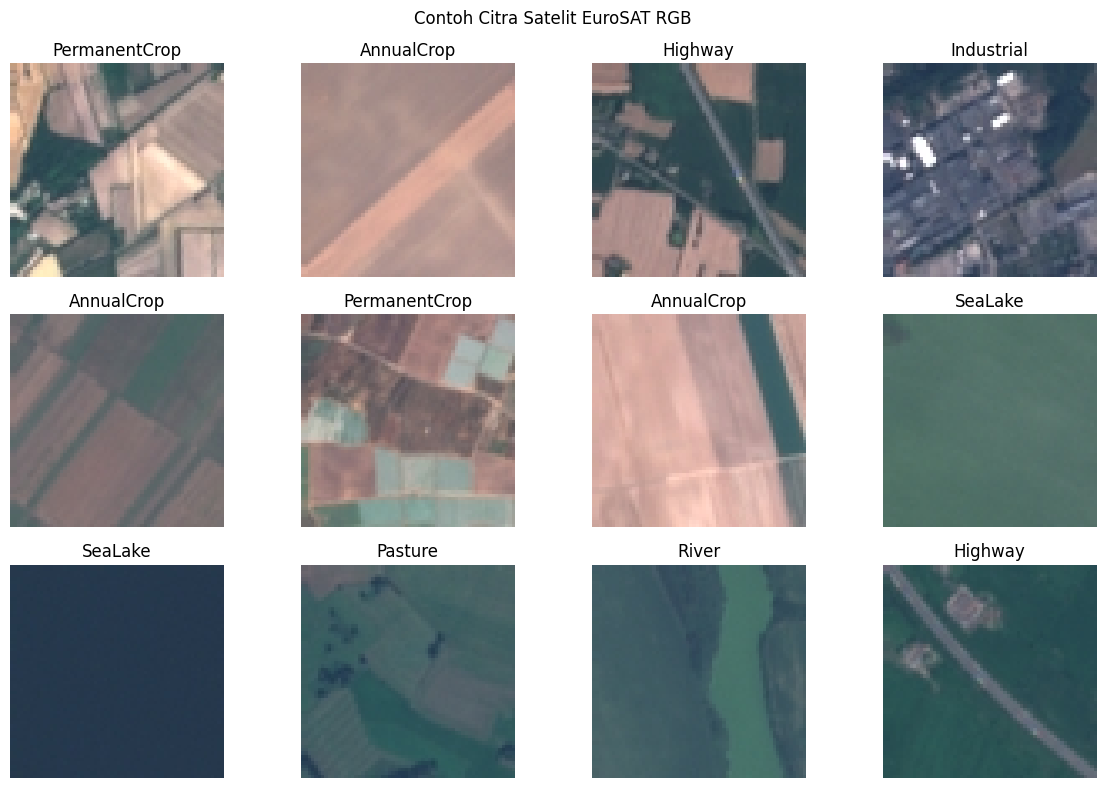

In [15]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Contoh Citra Satelit EuroSAT RGB")
plt.tight_layout()
plt.show()

,Kelas,Jumlah gambar
0,AnnualCrop,239
1,Forest,236
2,HerbaceousVegetation,213
3,Highway,195
4,Industrial,165
5,Pasture,143
6,PermanentCrop,176
7,Residential,232
8,River,165
9,SeaLake,236


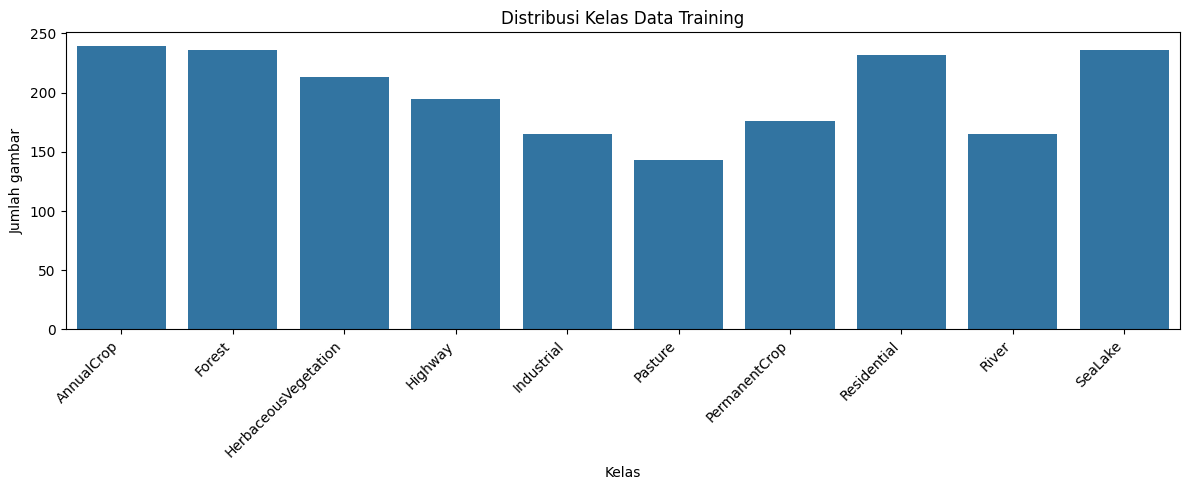

In [16]:
class_counts = pd.Series(y_train).value_counts().sort_index()

distribution = pd.DataFrame({
    "Kelas": [class_names[i] for i in class_counts.index],
    "Jumlah gambar": class_counts.values
})

display(distribution)

plt.figure(figsize=(12, 5))
sns.barplot(data=distribution, x="Kelas", y="Jumlah gambar")
plt.xticks(rotation=45, ha="right")
plt.title("Distribusi Kelas Data Training")
plt.tight_layout()
plt.show()

In [17]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_eurosat_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [19]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.1796 - loss: 2.1057
Epoch 1: val_loss improved from None to 1.60496, saving model to best_eurosat_cnn.keras

Epoch 1: finished saving model to best_eurosat_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 324ms/step - accuracy: 0.2420 - loss: 1.9645 - val_accuracy: 0.3960 - val_loss: 1.6050
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.3699 - loss: 1.6661
Epoch 2: val_loss improved from 1.60496 to 1.46057, saving model to best_eurosat_cnn.keras

Epoch 2: finished saving model to best_eurosat_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 300ms/step - accuracy: 0.3680 - loss: 1.6388 - val_accuracy: 0.3980 - val_loss: 1.4606
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - accuracy: 0.3975 - loss: 1.5110
Epoch 3: val_loss improved from 1.46057 to 1.33877, saving model to best_eurosat_cnn.keras

Epoch 3: finished saving model to best_eurosat_cnn.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 325ms/step - accuracy: 0.4005 -

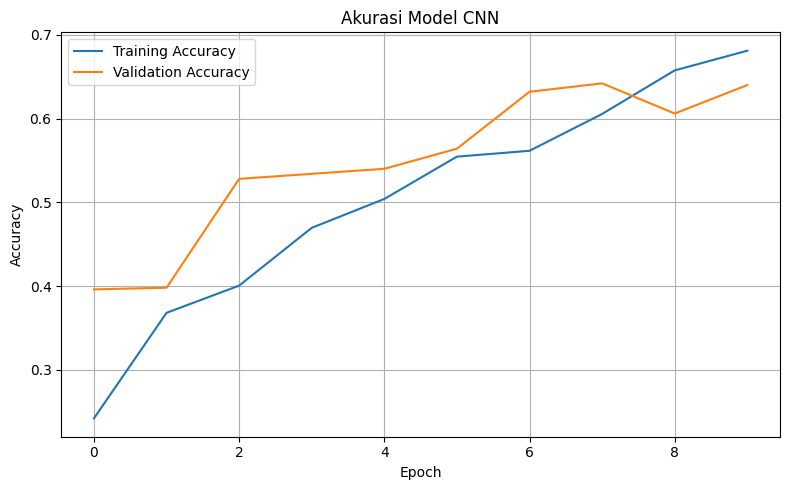

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Akurasi Model CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=150)
plt.show()

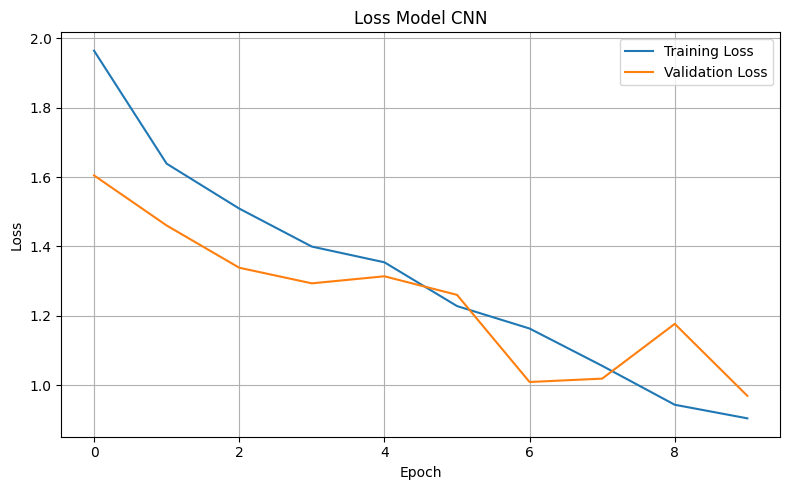

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Model CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [22]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.6660 - loss: 0.9519
Test Loss: 0.9519
Test Accuracy: 66.60%


In [23]:
y_prob = model.predict(X_test, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Contoh 10 prediksi pertama:")

for i in range(min(10, len(y_test))):
    print(
        f"Gambar {i + 1}: "
        f"aktual = {class_names[y_test[i]]}, "
        f"prediksi = {class_names[y_pred[i]]}"
    )

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step
Contoh 10 prediksi pertama:
Gambar 1: aktual = Industrial, prediksi = Industrial
Gambar 2: aktual = Highway, prediksi = Highway
Gambar 3: aktual = Industrial, prediksi = Industrial
Gambar 4: aktual = Residential, prediksi = Residential
Gambar 5: aktual = HerbaceousVegetation, prediksi = Residential
Gambar 6: aktual = Industrial, prediksi = PermanentCrop
Gambar 7: aktual = SeaLake, prediksi = SeaLake
Gambar 8: aktual = Industrial, prediksi = Industrial
Gambar 9: aktual = SeaLake, prediksi = SeaLake
Gambar 10: aktual = AnnualCrop, prediksi = AnnualCrop


In [24]:
report = classification_report(
    y_test,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(3))

report_df.to_csv("classification_report.csv")

,precision,recall,f1-score,support
AnnualCrop,0.764,0.792,0.778,53.000
Forest,0.875,0.667,0.757,63.000
HerbaceousVegetation,0.453,0.569,0.504,51.000
Highway,0.477,0.477,0.477,44.000
Industrial,0.864,0.559,0.679,34.000
Pasture,0.414,0.522,0.462,23.000
PermanentCrop,0.700,0.609,0.651,69.000
Residential,0.560,1.000,0.718,51.000
River,0.714,0.446,0.549,56.000
SeaLake,0.962,0.893,0.926,56.000


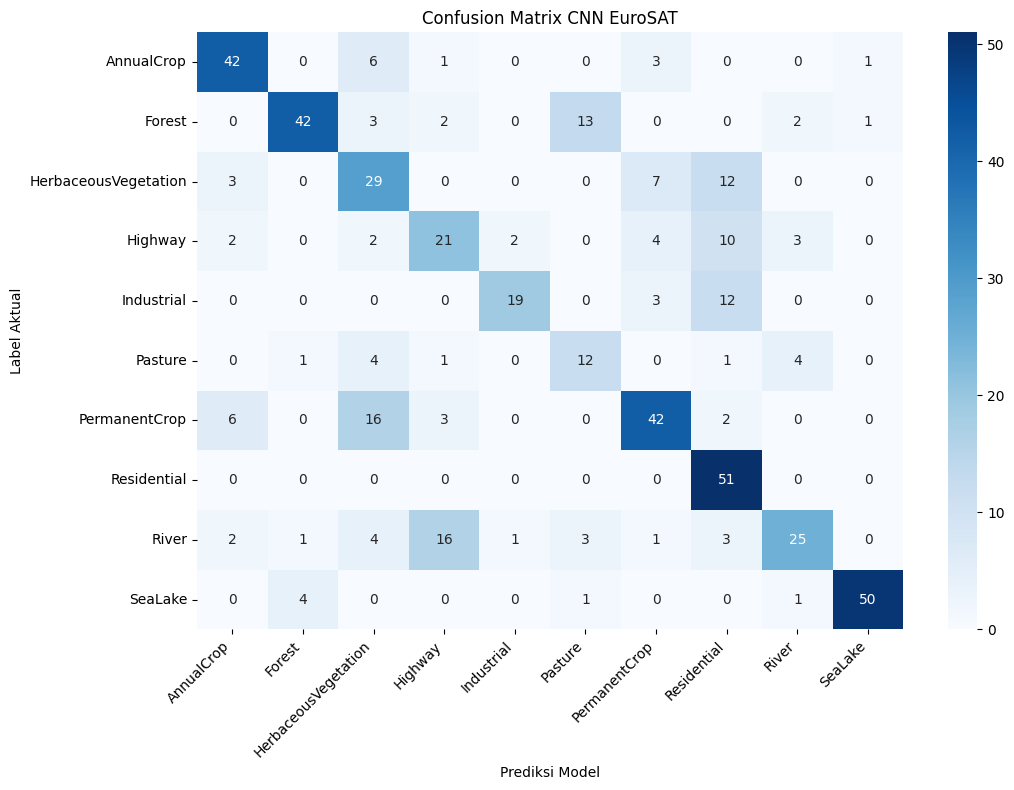

In [25]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.title("Confusion Matrix CNN EuroSAT")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

Jumlah prediksi salah: 167
Total gambar pengujian: 500


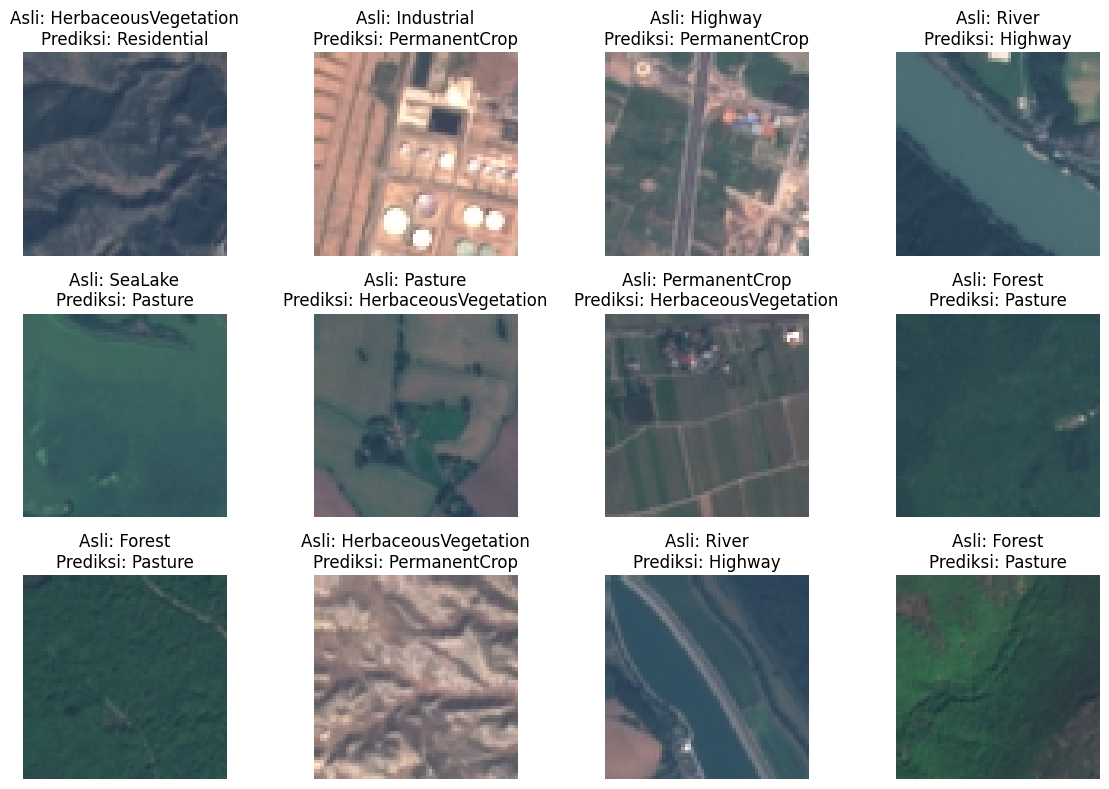

In [26]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Jumlah prediksi salah:", len(wrong_indices))
print("Total gambar pengujian:", len(y_test))

jumlah_tampil = min(12, len(wrong_indices))

if jumlah_tampil > 0:
    plt.figure(figsize=(12, 8))

    for j, idx in enumerate(wrong_indices[:jumlah_tampil]):
        plt.subplot(3, 4, j + 1)
        plt.imshow(X_test[idx])
        plt.title(
            f"Asli: {class_names[y_test[idx]]}\n"
            f"Prediksi: {class_names[y_pred[idx]]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada prediksi salah pada subset pengujian ini.")

In [27]:
model.save("eurosat_cnn_model.keras")

results = {
    "dataset": "timm/eurosat-rgb",
    "model": "CNN",
    "training_images": int(len(X_train)),
    "validation_images": int(len(X_val)),
    "test_images": int(len(X_test)),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "classes": class_names
}

with open("experiment_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model dan hasil eksperimen berhasil disimpan.")

Model dan hasil eksperimen berhasil disimpan.


In [28]:
from google.colab import files

files.download("eurosat_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
files.download("accuracy_curve.png")
files.download("loss_curve.png")
files.download("confusion_matrix.png")
files.download("classification_report.csv")
files.download("experiment_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>